# Baseline checkpoint: logistic regression with and without `PageValues`

Data: [Online Shoppers Purchasing Intention Dataset](https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset)
(UCI; Sakar & Kastro, 2018; CC BY 4.0).

Every feature is a session total, so the model predicts **after the session ends**.

Steps:
1. Load the data and confirm 12,330 sessions and a 15.5% purchase rate.
2. Set aside a stratified 20% test set. It is not used again until the final evaluation.
3. On the remaining 80%, tune an L1 (lasso) logistic regression by stratified 5-fold CV, scored by average precision,
   with and without `PageValues`, and compare CV average precision with the constant-score floor.

In [1]:
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

RANDOM_STATE = 42
DATA_PATH = "online_shoppers_intention.csv"   # the CSV inside the UCI zip

## Step 1: Load and check the data

In [2]:
try:
    df = pd.read_csv(DATA_PATH)
except FileNotFoundError:
    # Fallback: pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=468)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)

df["Weekend"] = df["Weekend"].astype(int)
df["Revenue"] = df["Revenue"].astype(int)

n_sessions = len(df)
purchase_rate = df["Revenue"].mean()
print(f"Sessions: {n_sessions:,}")
print(f"Purchase rate: {purchase_rate:.3%}")
print(f"Missing values: {df.isna().sum().sum()}")

assert n_sessions == 12330, "Expected 12,330 sessions"
assert abs(purchase_rate - 0.155) < 0.001, "Expected a 15.5% purchase rate"

Sessions: 12,330
Purchase rate: 15.474%
Missing values: 0


## Step 2: Set aside the test set

Stratified, so the test set keeps the 15.5% purchase rate. `X_test` and `y_test` are not used again until the final evaluation.

In [3]:
X = df.drop(columns="Revenue")
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train):,} sessions, purchase rate {y_train.mean():.3%}")
print(f"Test:  {len(X_test):,} sessions, purchase rate {y_test.mean():.3%}")

Train: 9,864 sessions, purchase rate 15.470%
Test:  2,466 sessions, purchase rate 15.491%


## Step 3: Lasso logistic regression, tuned by stratified 5-fold CV

One-hot encoding, scaling and the lasso all sit inside one `Pipeline`, so in every CV fold they are fitted on the training part only.
`C` is tuned over a log grid, scored by average precision.

In [4]:
CATEGORICAL = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
C_GRID = np.logspace(-3, 2, 11)          # 0.001 ... 100
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_l1_logreg():
    # scikit-learn 1.8+ replaced penalty="l1" with l1_ratio=1
    major, minor = (int(v) for v in sklearn.__version__.split(".")[:2])
    if (major, minor) >= (1, 8):
        return LogisticRegression(l1_ratio=1, solver="liblinear", max_iter=5000)
    return LogisticRegression(penalty="l1", solver="liblinear", max_iter=5000)


def build_pipeline(columns):
    categorical = [c for c in CATEGORICAL if c in columns]
    numeric = [c for c in columns if c not in categorical]
    preprocess = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ("num", StandardScaler(), numeric),
    ])
    return Pipeline([("prep", preprocess), ("model", make_l1_logreg())])


def run_cv(X_tr, y_tr, label):
    search = GridSearchCV(
        build_pipeline(list(X_tr.columns)),
        param_grid={"model__C": C_GRID},
        scoring="average_precision",
        cv=CV,
    )
    search.fit(X_tr, y_tr)
    i = search.best_index_
    fold_ap = np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(CV.n_splits)])
    coef = search.best_estimator_.named_steps["model"].coef_.ravel()
    row = {
        "Model": label,
        "Best C": search.best_params_["model__C"],
        "Features kept": f"{(coef != 0).sum()} / {coef.size}",
        "CV AP mean": fold_ap.mean(),
        "CV AP SD": fold_ap.std(ddof=1),
        "CV AP min": fold_ap.min(),
        "CV AP max": fold_ap.max(),
    }
    return search, row

In [5]:
search_with, row_with = run_cv(X_train, y_train, "Lasso LR, with PageValues")
search_without, row_without = run_cv(X_train.drop(columns="PageValues"), y_train, "Lasso LR, without PageValues")

floor = {"Model": "Constant score (floor = purchase rate)", "CV AP mean": y_train.mean()}

results = pd.DataFrame([floor, row_with, row_without])
results.round(3)

,Model,CV AP mean,Best C,Features kept,CV AP SD,CV AP min,CV AP max
0,Constant score (floor = purchase rate),0.155,NaN,NaN,NaN,NaN,NaN
1,"Lasso LR, with PageValues",0.665,0.003,4 / 74,0.021,0.640,0.693
2,"Lasso LR, without PageValues",0.332,0.100,23 / 73,0.022,0.312,0.367


**Reading the table.** A model with no skill gets average precision equal to the purchase rate (about 0.155), so that is the floor.
The fold min–max shows how much the score moves between folds; a with-vs-without gap smaller than that spread is weak evidence.
Accuracy and F1 are secondary; if a threshold is needed, choose it on the validation folds, never on the test set.

### Figure: CV average precision with and without `PageValues`

Bars show the mean over the 5 folds with ±1 standard error (SD / √5); dots are the individual folds.
The dashed line is the constant-score floor. Saved as `baseline.png`.

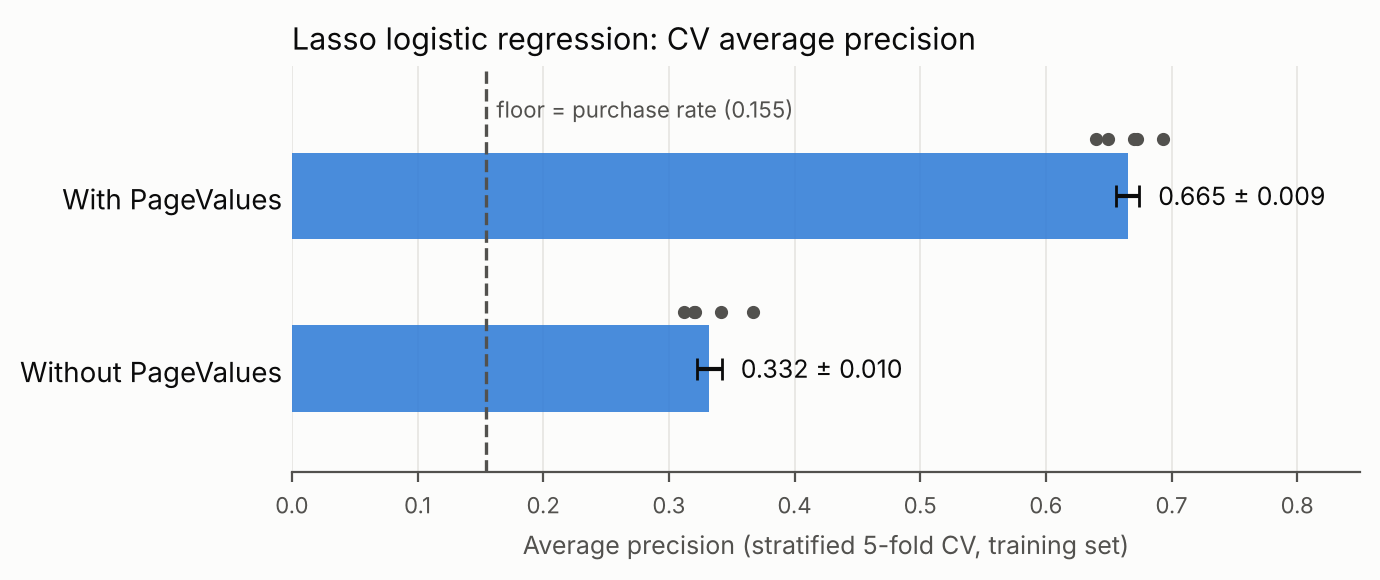

In [6]:
import matplotlib.pyplot as plt


def fold_scores(search):
    i = search.best_index_
    return np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(CV.n_splits)])


labels = ["With PageValues", "Without PageValues"]
folds = [fold_scores(search_with), fold_scores(search_without)]
means = [f.mean() for f in folds]
ses = [f.std(ddof=1) / np.sqrt(len(f)) for f in folds]

BLUE, INK, MUTED, SURFACE = "#2a78d6", "#0b0b0b", "#52514e", "#fcfcfb"
fig, ax = plt.subplots(figsize=(7, 3), dpi=200, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
y = np.arange(len(labels))[::-1]
ax.barh(y, means, height=0.5, color=BLUE, alpha=0.85)
ax.errorbar(means, y, xerr=ses, fmt="none", ecolor=INK, elinewidth=1.5, capsize=4)
for yi, f in zip(y, folds):
    ax.scatter(f, np.full_like(f, yi) + 0.33, s=14, color=MUTED, zorder=3)
for yi, m, s in zip(y, means, ses):
    ax.text(m + s + 0.015, yi, f"{m:.3f} ± {s:.3f}", va="center", color=INK, fontsize=9)
floor_ap = y_train.mean()
ax.axvline(floor_ap, color=MUTED, linestyle="--", linewidth=1.2)
ax.text(floor_ap + 0.008, y.max() + 0.5, f"floor = purchase rate ({floor_ap:.3f})", color=MUTED, fontsize=8, va="center")
ax.set_yticks(y, labels, color=INK)
ax.set_xlim(0, 0.85)
ax.set_ylim(-0.6, y.max() + 0.75)
ax.set_xlabel("Average precision (stratified 5-fold CV, training set)", color=MUTED, fontsize=9)
ax.set_title("Lasso logistic regression: CV average precision", color=INK, fontsize=11, loc="left")
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(MUTED)
ax.tick_params(axis="x", colors=MUTED, labelsize=8)
ax.tick_params(axis="y", length=0)
ax.grid(axis="x", color="#e6e5e1", linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("baseline.png", facecolor=SURFACE)
plt.show()

### Secondary metrics: accuracy and F1

These need a decision threshold. Each training session is scored by a model fitted on the other four folds (out-of-fold
predictions), and the threshold that maximizes F1 on those scores is kept. The test set plays no part in choosing it.
For comparison, always predicting "no purchase" gives accuracy equal to 1 minus the purchase rate and an F1 of 0.

In [7]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, accuracy_score, f1_score, precision_score, recall_score


def secondary_metrics(search, X_tr, y_tr, label):
    oof = cross_val_predict(search.best_estimator_, X_tr, y_tr, cv=CV, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_tr, oof)
    f1 = 2 * prec[:-1] * rec[:-1] / np.clip(prec[:-1] + rec[:-1], 1e-12, None)
    threshold = thr[np.argmax(f1)]
    pred = (oof >= threshold).astype(int)
    row = {
        "Model": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_tr, pred),
        "Precision": precision_score(y_tr, pred),
        "Recall": recall_score(y_tr, pred),
        "F1": f1_score(y_tr, pred),
    }
    return threshold, row


t_with, sec_with = secondary_metrics(search_with, X_train, y_train, "Lasso LR, with PageValues")
t_without, sec_without = secondary_metrics(
    search_without, X_train.drop(columns="PageValues"), y_train, "Lasso LR, without PageValues"
)
majority = {"Model": 'Always "no purchase"', "Accuracy": 1 - y_train.mean(), "Precision": 0.0, "Recall": 0.0, "F1": 0.0}

secondary = pd.DataFrame([majority, sec_with, sec_without])
secondary.round(3)

,Model,Accuracy,Precision,Recall,F1,Threshold
0,"Always ""no purchase""",0.845,0.000,0.000,0.000,NaN
1,"Lasso LR, with PageValues",0.887,0.611,0.737,0.668,0.183
2,"Lasso LR, without PageValues",0.728,0.305,0.590,0.402,0.210


## Final evaluation (run once, at the end of the project)

Leave `RUN_FINAL_TEST = False` until every model choice is made. Then the test set is used once:
each model's test AP, and a paired bootstrap 95% interval for the with-vs-without gap. An interval that contains 0 is a tie.

In [8]:
RUN_FINAL_TEST = False
N_BOOT = 2000


def paired_bootstrap_gap(y_true, score_a, score_b, n_boot=N_BOOT, seed=RANDOM_STATE):
    # Resample the same test sessions for both models, so the gap is paired.
    rng = np.random.default_rng(seed)
    y_true, score_a, score_b = map(np.asarray, (y_true, score_a, score_b))
    gaps = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].sum() == 0:
            continue
        gaps.append(average_precision_score(y_true[idx], score_a[idx])
                    - average_precision_score(y_true[idx], score_b[idx]))
    return np.percentile(gaps, [2.5, 97.5])


if RUN_FINAL_TEST:
    p_with = search_with.predict_proba(X_test)[:, 1]
    p_without = search_without.predict_proba(X_test.drop(columns="PageValues"))[:, 1]
    ap_with = average_precision_score(y_test, p_with)
    ap_without = average_precision_score(y_test, p_without)
    lo, hi = paired_bootstrap_gap(y_test, p_with, p_without)
    print(f"Test AP with PageValues:    {ap_with:.3f}")
    print(f"Test AP without PageValues: {ap_without:.3f}")
    print(f"Gap: {ap_with - ap_without:.3f}  (95% paired bootstrap CI: {lo:.3f} to {hi:.3f})")
    print(f"Test floor (purchase rate): {y_test.mean():.3f}")

    # Secondary metrics, using the thresholds chosen on the training folds
    for label, p, t in [("with PageValues", p_with, t_with), ("without PageValues", p_without, t_without)]:
        pred = (p >= t).astype(int)
        print(f"{label}: accuracy {accuracy_score(y_test, pred):.3f}, F1 {f1_score(y_test, pred):.3f}")